# Data Free Metrics Do Not Work: LLM Example Pythia-1B

This notebook goes the proccess for Pythia-1B model used in paper, evaluating it with weightwatcher, randomising the layers and observing the new performance and metrics.

**If you are using Google Colab please run the pip command as all other packages are already in the environment.**

In [1]:
! pip install weightwatcher

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [weightwatcher]


 Import the required packages.

In [2]:
import math

import matplotlib.pyplot as plt
import torch
import weightwatcher as ww
from datasets import load_dataset
from torch.utils.data import Dataset
from tqdm import tqdm
from transformers import AutoTokenizer, GPTNeoXForCausalLM

## 1.Setup Dataset for Evaluation

### 1.1 Create Dataset Class

In [3]:
class WikitextDataset(Dataset):
    """Simple dataset."""

    def __init__(self, data, block_size):
        self.data = data["input_ids"]
        self.block_size = block_size

    def __len__(self):
        return len(self.data[0]) - self.block_size

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()
        sample = torch.unsqueeze(self.data[0][idx:idx+self.block_size], dim=0)
        target = torch.unsqueeze(self.data[0][idx+1: idx+1+self.block_size], dim=0)
        return sample, target

### 1.2 Create Evaluation Function

In [4]:

def evaluate_model(model, dataset, max_input_length:int, stride:int, device):
    model.to(device)
    model.eval()
    max_length = max_input_length
    seq_len = len(dataset)
    nll_sum = 0.0
    n_tokens = 0
    correct = 0
    total = 0
    for i in tqdm(range(0, seq_len-max_length, stride)):
        inputs, targets = dataset.__getitem__(i)
        inputs = inputs.to(device)
        targets = targets.to(device)

        with torch.no_grad():
            outputs = model(inputs, labels=inputs)
            # loss is calculated using CrossEntropyLoss which averages over valid labels
            # N.B. the model only calculates loss over trg_len - 1 labels, because it internally shifts the labels to the left by 1.
            neg_log_likelihood = outputs.loss
        preds = torch.argmax(outputs.logits, axis=2)
        correct+= torch.sum(preds == targets)
        total += len(targets.flatten())

        # Accumulate the total negative log-likelihood and the total number of tokens
        num_valid_tokens = (inputs != -100).sum().item()  # number of valid tokens in target_ids
        batch_size = inputs.size(0)
        num_loss_tokens = num_valid_tokens - batch_size  # subtract batch_size due to internal label shift
        nll_sum += neg_log_likelihood * num_loss_tokens
        n_tokens += num_loss_tokens

    avg_nll = nll_sum / n_tokens  # average negative log-likelihood per token
    ppl = torch.exp(avg_nll)
    return ppl.item(), avg_nll.item(), (correct/total).item()*100

### 1.3 Get Dataset

In [5]:
test_dataset = load_dataset("salesforce/wikitext", "wikitext-2-raw-v1", split="test")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/validation-00000-of-00(…): reconstructing file:   0%|          |  0.00B /  657kB            

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

## 2.Get Pythia Model

Initialisation methods see https://github.com/eleutherai/pythia#reproducing-training

In [6]:
def small_init_init_method(hidden_size):
    """Fills the input Tensor with values according to the method described in Transformers without Tears: Improving
    the Normalization of Self-Attention - Nguyen, T. & Salazar, J. (2010), using a normal distribution."""
    std = math.sqrt(2 / (5 * hidden_size))

    def init_(tensor):
        return torch.nn.init.normal_(tensor, mean=0.0, std=std)

    return init_


def wang_init_method(num_layers, hidden_size):
    std = 2 / num_layers / math.sqrt(hidden_size)

    def init_(tensor):
        return torch.nn.init.normal_(tensor, mean=0.0, std=std)

    return init_

In [8]:
model_name = "pythia-1b"
tokenizer = AutoTokenizer.from_pretrained(
      f"EleutherAI/{model_name}",
  )
# Trained Model
trained_model = GPTNeoXForCausalLM.from_pretrained(f"EleutherAI/{model_name}")
# Initialised Model
init_model = GPTNeoXForCausalLM.from_pretrained(f"EleutherAI/{model_name}", revision="step0")
# Random Model
random_model = GPTNeoXForCausalLM(trained_model.config)
small_init = small_init_init_method(hidden_size=trained_model.config.hidden_size)
output_init = wang_init_method(num_layers=trained_model.config.num_hidden_layers, hidden_size=trained_model.config.hidden_size)

for n, m in random_model.named_modules():
    if isinstance(m, torch.nn.Linear) or isinstance(m, torch.nn.Embedding):
        if "attention.dense" in n or "mlp.dense_4h_to_h" in n:
            output_init(m.weight)
        else:
            small_init(m.weight)

if trained_model.config.dtype == torch.float16:
  random_model.to(torch.float16)

config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.05GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

###2.1 Trained Model Details

**Data Free Metrics**

In [9]:
watcher = ww.WeightWatcher(model=trained_model)
trained_details = watcher.analyze(mp_fit=True)
trained_details

,layer_id,name,D,M,N,Q,W_scale,alpha,alpha_weighted,bulk_max,...,sigma_mp,spectral_norm,stable_rank,status,sv_max,sv_min,warning,weak_rank_loss,xmax,xmin
0,11,query_key_value,0.043728,2048,6144,3.0,0.507513,4.816122,9.806756,7.341036,...,0.871762,108.701332,73.147605,success,10.425993,2.622795e-01,,0,108.701332,8.573026
1,12,dense,0.041772,2048,2048,1.0,1.229142,3.402655,4.894023,2.709550,...,1.011627,27.434395,49.411788,success,5.237785,1.380533e-07,,4,27.434395,2.313073
2,14,dense_h_to_4h,0.067050,2048,8192,4.0,0.482986,7.696037,16.214376,8.134451,...,0.918347,127.893219,68.645835,success,11.308989,7.212410e-01,under-trained,0,127.893219,6.620087
3,15,dense_4h_to_h,0.069509,2048,8192,4.0,0.719836,8.826775,13.568604,4.218780,...,0.985680,34.451614,114.723663,success,5.869550,1.202396e-01,under-trained,0,34.451614,2.904908
4,23,query_key_value,0.039273,2048,6144,3.0,0.521638,3.736835,6.990953,5.121268,...,0.748392,74.271400,101.337622,success,8.618086,2.414911e-01,,0,74.271400,12.864963
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,183,dense_4h_to_h,0.044433,2048,8192,4.0,0.381635,5.834334,12.425768,14.690907,...,0.975171,134.823715,104.296034,success,11.611362,1.610977e-01,,0,134.823715,11.386006
60,191,query_key_value,0.028711,2048,6144,3.0,0.522019,4.736725,8.264263,7.878923,...,0.928948,55.554680,135.281218,success,7.453501,4.128652e-01,,0,55.554680,6.931876
61,192,dense,0.062214,2048,2048,1.0,0.883191,6.113733,8.510132,5.193348,...,1.006348,24.658684,106.475788,success,4.965751,3.168315e-04,under-trained,1,24.658684,3.469756
62,194,dense_h_to_4h,0.011493,2048,8192,4.0,0.476631,3.613137,7.564751,7.789473,...,0.886839,124.073578,72.658555,success,11.138832,2.499453e-01,,0,124.073578,6.994755


In [10]:
analysed_layers = trained_details["longname"]

$2\leq\alpha\leq6$ is considered a good layer and or model.

In [11]:
print("Layer Alpha", trained_details["alpha"])
print(f"Model Alpha: {trained_details["alpha"].mean()}")

Layer Alpha 0     4.816122
1     3.402655
2     7.696037
3     8.826775
4     3.736835
        ...   
59    5.834334
60    4.736725
61    6.113733
62    3.613137
63    4.329716
Name: alpha, Length: 64, dtype: float64
Model Alpha: 4.800604517320853


**Model Performance**

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
stride = 1024
max_input_length = trained_model.config.max_position_embeddings
encodings = tokenizer("\n\n".join(test_dataset["text"]), return_tensors="pt")
dataset = WikitextDataset(encodings,  trained_model.config.max_position_embeddings)
base_perplexity, base_nll, base_acc = evaluate_model(trained_model, dataset, max_input_length, stride, device)
trained_model.to("cpu")
print(f"Perplexity: {base_perplexity:.3f}, Loss: {base_nll:.3f}, Accuracy: {base_acc:.3f}%")

100%|██████████| 278/278 [01:17<00:00,  3.60it/s]


Perplexity: 13.138, Loss: 2.576, Accuracy: 47.678%


###2.2 Initalised Model Details

**Data Free Metrics**

In [13]:
watcher = ww.WeightWatcher(model=init_model)
init_details = watcher.analyze(mp_fit=True)
init_details

,layer_id,name,D,M,N,Q,W_scale,alpha,alpha_weighted,bulk_max,...,sigma_mp,spectral_norm,stable_rank,status,sv_max,sv_min,warning,weak_rank_loss,xmax,xmin
0,11,query_key_value,0.120384,2048,6144,3.0,0.912546,18.501251,8.767181,3.020228,...,1.005418,2.977623,825.944025,success,1.725579,0.465960,under-trained,0,2.977623,2.596918
1,12,dense,0.128772,2048,2048,1.0,7.994954,6.792981,-8.196084,0.063462,...,1.007032,0.062151,515.525118,success,0.249301,0.000033,under-trained,11,0.062151,0.041329
2,14,dense_h_to_4h,0.121592,2048,8192,4.0,0.790626,23.107215,12.856370,3.625996,...,1.003676,3.600634,909.930630,success,1.897534,0.634728,under-trained,0,3.600634,3.215633
3,15,dense_4h_to_h,0.107952,2048,8192,4.0,3.999697,84.504231,-71.993689,0.141665,...,1.003616,0.140620,910.394186,success,0.374993,0.124884,under-trained,0,0.140620,0.136113
4,23,query_key_value,0.110434,2048,6144,3.0,0.912875,31.118674,14.771750,3.018907,...,1.005560,2.983258,823.789546,success,1.727211,0.462528,under-trained,0,2.983258,2.746600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,183,dense_4h_to_h,0.114393,2048,8192,4.0,3.999892,20.994129,-17.920858,0.141427,...,1.002822,0.140084,913.789774,success,0.374277,0.125473,under-trained,0,0.140084,0.123973
60,191,query_key_value,0.116434,2048,6144,3.0,0.912963,29.367820,13.888794,3.015424,...,1.005077,2.971157,826.985903,success,1.723704,0.465770,under-trained,0,2.971157,2.732810
61,192,dense,0.125269,2048,2048,1.0,7.998471,31.195350,-37.624478,0.063405,...,1.007024,0.062217,514.527398,success,0.249433,0.000090,under-trained,11,0.062217,0.057263
62,194,dense_h_to_4h,0.111368,2048,8192,4.0,0.790497,38.184519,21.253197,3.603808,...,1.000438,3.602400,909.781541,success,1.897999,0.631786,under-trained,0,3.602400,3.365878


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


$2\leq\alpha\leq6$ is considered a good layer and or model.

In [14]:
print("Layer Alpha", init_details["alpha"])
print(f"Model Alpha: {init_details["alpha"].mean()}")

Layer Alpha 0     18.501251
1      6.792981
2     23.107215
3     84.504231
4     31.118674
        ...    
59    20.994129
60    29.367820
61    31.195350
62    38.184519
63    51.378151
Name: alpha, Length: 64, dtype: float64
Model Alpha: 27.956261361919296


**Model Performance**

In [15]:
init_perplexity, init_nll, init_acc = evaluate_model(init_model, dataset, max_input_length, stride, device)
init_model.to("cpu")
print(f"Perplexity: {init_perplexity:.3f}, Loss: {init_nll:.3f}, Accuracy: {init_acc:.3f}%")


100%|██████████| 278/278 [01:16<00:00,  3.65it/s]


Perplexity: 61247.797, Loss: 11.023, Accuracy: 0.001%


###2.3 Random Model Details

In [16]:
watcher = ww.WeightWatcher(model=random_model)
random_details = watcher.analyze(mp_fit=True)
random_details

,layer_id,name,D,M,N,Q,W_scale,alpha,alpha_weighted,bulk_max,...,sigma_mp,spectral_norm,stable_rank,status,sv_max,sv_min,warning,weak_rank_loss,xmax,xmin
0,11,query_key_value,0.121046,2048,6144,3.0,0.912616,18.301760,8.678924,3.019098,...,1.005307,2.979974,825.165167,success,1.726260,0.466843,under-trained,0,2.979974,2.584116
1,12,dense,0.116232,2048,2048,1.0,7.995746,26.956543,-32.544733,0.063427,...,1.006850,0.062044,516.316044,success,0.249085,0.000066,under-trained,9,0.062044,0.056369
2,14,dense_h_to_4h,0.117186,2048,8192,4.0,0.790376,15.246186,8.479842,3.627276,...,1.003536,3.599103,910.893909,success,1.897130,0.635683,under-trained,0,3.599103,3.027172
3,15,dense_4h_to_h,0.119913,2048,8192,4.0,4.000214,14.027807,-11.969266,0.141490,...,1.003123,0.140200,912.885459,success,0.374433,0.124426,under-trained,0,0.140200,0.116337
4,23,query_key_value,0.123817,2048,6144,3.0,0.913009,11.950453,5.664833,3.017220,...,1.005427,2.978699,824.808111,success,1.725891,0.467622,under-trained,0,2.978699,2.390733
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,183,dense_4h_to_h,0.120153,2048,8192,4.0,4.000212,15.596575,-13.331003,0.141279,...,1.002376,0.139721,916.015904,success,0.373792,0.125018,under-trained,0,0.139721,0.118815
60,191,query_key_value,0.123288,2048,6144,3.0,0.912460,58.259842,27.578692,3.018538,...,1.005042,2.974226,827.043051,success,1.724594,0.465400,under-trained,0,2.974226,2.853603
61,192,dense,0.110187,2048,2048,1.0,8.002511,26.339300,-31.792129,0.063344,...,1.007045,0.062084,515.109895,success,0.249166,0.000075,under-trained,10,0.062084,0.056281
62,194,dense_h_to_4h,0.121758,2048,8192,4.0,0.790333,11.652725,6.455245,3.619935,...,1.002465,3.580706,915.675118,success,1.892275,0.634478,under-trained,0,3.580706,2.865257


$2\leq\alpha\leq6$ is considered a good layer and or model.

In [17]:
print("Layer Alpha", random_details["alpha"])
print(f"Model Alpha: {random_details["alpha"].mean()}")

Layer Alpha 0     18.301760
1     26.956543
2     15.246186
3     14.027807
4     11.950453
        ...    
59    15.596575
60    58.259842
61    26.339300
62    11.652725
63    25.180526
Name: alpha, Length: 64, dtype: float64
Model Alpha: 26.58458093237575


**Model Performance**

In [18]:
random_perplexity, random_nll, random_acc = evaluate_model(random_model, dataset, max_input_length, stride, device)
random_model.to("cpu")
print(f"Perplexity: {random_perplexity:.3f}, Loss: {random_nll:.3f}, Accuracy: {random_acc:.3f}%")

100%|██████████| 278/278 [01:17<00:00,  3.57it/s]


Perplexity: 63466.812, Loss: 11.058, Accuracy: 0.000%


## 3.Reinitialising and Rerandomising the Layers
This section demonstrates how reinitialising and rerandomising the layers affects the performance of the model and the corresponding data free metrics.

### 3.1 Evalulate Layers

In [19]:
performance = {"init": {}, "random": {}}
for layer_name in analysed_layers[:5]: # We only do a subset here for demonstation reasons.
    for idx, change_model in enumerate([init_model, random_model]):
      trained_model = GPTNeoXForCausalLM.from_pretrained(f"EleutherAI/{model_name}")
      trained_model.set_submodule(layer_name, change_model.get_submodule(layer_name))
      perplexity, loss, acc = evaluate_model(trained_model, dataset, max_input_length, stride, device)
      if idx == 0:
          performance["init"][layer_name] = {"acc": acc, "loss": loss}
      else:
          performance["random"][layer_name] = {"acc": acc, "loss": loss}
      del trained_model

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

100%|██████████| 278/278 [01:15<00:00,  3.67it/s]


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

100%|██████████| 278/278 [01:15<00:00,  3.69it/s]


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

...

100%|██████████| 278/278 [01:14<00:00,  3.75it/s]


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

100%|██████████| 278/278 [01:15<00:00,  3.69it/s]


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

100%|██████████| 278/278 [01:15<00:00,  3.68it/s]


In [20]:
performance

{'init': {'gpt_neox.layers.0.attention.query_key_value': {'acc': 37.1492475271225,
   'loss': 3.435208559036255},
  'gpt_neox.layers.0.attention.dense': {'acc': 18.63776594400406,
   'loss': 5.440605640411377},
  'gpt_neox.layers.0.mlp.dense_h_to_4h': {'acc': 0.22165861446410418,
   'loss': 9.842791557312012},
  'gpt_neox.layers.0.mlp.dense_4h_to_h': {'acc': 0.08219986921176314,
   'loss': 10.888309478759766},
  'gpt_neox.layers.1.attention.query_key_value': {'acc': 39.406055212020874,
   'loss': 3.2320432662963867}},
 'random': {'gpt_neox.layers.0.attention.query_key_value': {'acc': 33.72952044010162,
   'loss': 3.7667946815490723},
  'gpt_neox.layers.0.attention.dense': {'acc': 18.217985332012177,
   'loss': 5.487448692321777},
  'gpt_neox.layers.0.mlp.dense_h_to_4h': {'acc': 0.025116626056842506,
   'loss': 11.453764915466309},
  'gpt_neox.layers.0.mlp.dense_4h_to_h': {'acc': 0.16633177874609828,
   'loss': 10.57938003540039},
  'gpt_neox.layers.1.attention.query_key_value': {'acc':

### 3.2 Plot the Relationship: Data-Free Metric Vs Test Accuracy

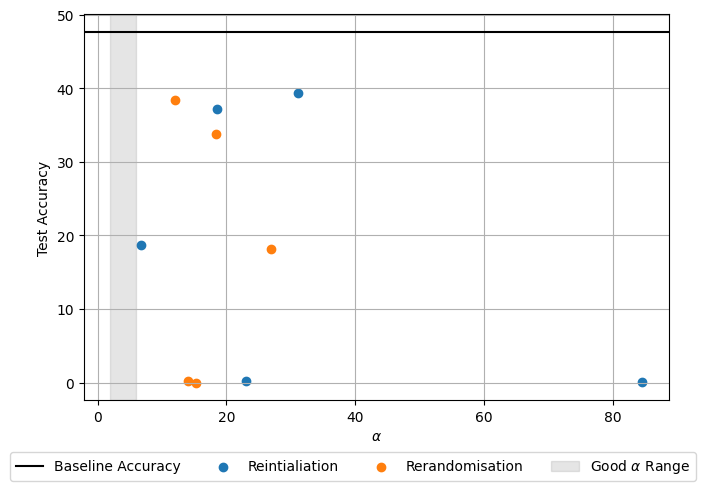

In [21]:
fig, ax = plt.subplots(constrained_layout=True)

baseline = ax.axhline(base_acc, color="k")
for idx, layer_name in enumerate(analysed_layers[:5]):
  inits = ax.scatter(init_details["alpha"][idx], performance["init"][analysed_layers[idx]]["acc"], color="tab:blue")
  randoms = ax.scatter(random_details["alpha"][idx], performance["random"][analysed_layers[idx]]["acc"], color="tab:orange")
ax.grid()

alpha_range = ax.axvspan(2,6, color="grey", alpha=0.2)
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"Test Accuracy")
fig.legend([baseline, inits, randoms, alpha_range], ["Baseline Accuracy", "Reintialiation", "Rerandomisation", r"Good $\alpha$ Range"], loc='outside lower center', ncol=4)
plt.show()